# INF201 – Deliverable 1

## Introduction
This notebook contains Python code and explanations.

In [36]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
from getpass import getpass


## Task 1: Temperature

In this task, we will retrive daily mean air temperature data from the Ås weather station for the year 2025. 

In [40]:
client_id = getpass("Enter your Frost Client ID: ")

In [17]:
endpoint = "https://frost.met.no/observations/v0.jsonld"

parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)", 
    "referencetime": "2025-01-01/2026-01-01",
}

In [ ]:
#Frost API request based on the approach shown in MET Norway's Phython exple.
response = requests.get(
    endpoint, 
    params=parameters, 
    auth=(client_id, "")
)

print(response.status_code)

200


In [32]:
data = response.json()


In [ ]:
temperatures = []

# Extract one dauly mean temperature per date using the PT0H time offset.
for day in data["data"]:
    for observation in day["observations"]:
        if observation["timeOffset"] == "PT0H":
            temperatures.append({
                "date": day["referenceTime"], 
                "temperature": observation["value"]
            })



In [34]:
df = pd.DataFrame(temperatures)

df["date"] = pd.to_datetime(df["date"])

print("Number of days:", len(df))

Number of days: 365


In [ ]:
# Calculate summary statistics for the daily mean temperatures.
mean_temp = df["temperature"].mean()
median_temp = df["temperature"].median()
min_temp = df["temperature"].min()
max_temp = df["temperature"].max()




In [26]:
print("Temperature summary - Ås, 2025")
print("-" *35)
print(f"{'Mean:':<12} {mean_temp:>8.2f} °C")
print(f"{'Median:':<12} {median_temp:>8.2f} °C")
print(f"{'Minimum:':<12} {min_temp:>8.2f} °C")
print(f"{'Maximum:':<12} {max_temp:>8.2f} °C")

Temperature summary - Ås, 2025
-----------------------------------
Mean:            7.87 °C
Median:          8.30 °C
Minimum:       -15.50 °C
Maximum:        23.70 °C


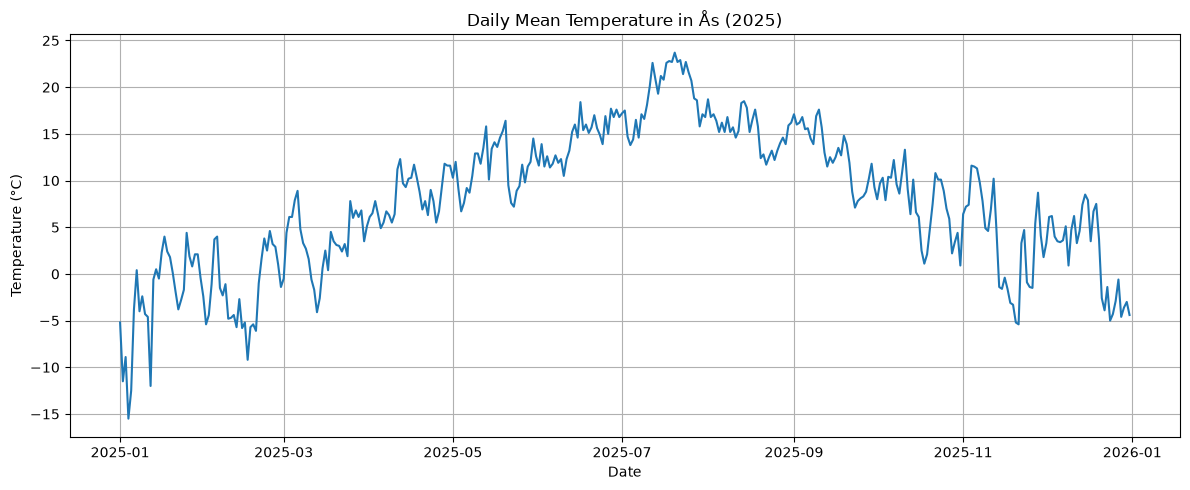

In [29]:
plt.figure(figsize=(12,5))

plt.plot(df["date"], df["temperature"])

plt.title("Daily Mean Temperature in Ås (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.grid(True)
plt.tight_layout()
plt.show()

## Results and discussion
We can see on the graph that the daily mean air temperature in Ås varies throughout 2025. The highest daily mean temperature was 23.7 °C and the lowest around -15.5°C, The temperature wa increasing when it was somer time, and starts to go down when it is on the way to  fall seson.
The median was 8.30 °C and the annual mean 7.87 °C.
In this analysis we used the PT0H time series, that represents the daily mean temperatures from midnight to midnight, following the preferred time offset in the Frost documentation (MET Norway, nd.). 


## Task 2: Precipitation
For this task daily precipitation data from Ås in 2025 are retrived from the Frost API and plotted together with daily mean temperature.

In [38]:
# Define the parameters for daily precipitation in 2025.
precip_parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01",
}

In [41]:
# Request daily precipitation data from the Frost API.
precip_response = requests.get(
    endpoint,
    params=precip_parameters,
    auth=(client_id, "")
)

print("Status code:", precip_response.status_code)

Status code: 200


In [42]:
precip_data = precip_response.json()


In [50]:
precipitation = []

# Select one consistent 24-hour precipitation series.
for day in precip_data["data"]:
    for observation in day["observations"]:
        if observation["timeOffset"] == "PT6H":
            precipitation.append({
                "date": day["referenceTime"], 
                "precipitation": observation["value"]
            })

In [52]:
precip_df = pd.DataFrame(precipitation)

precip_df["date"] = pd.to_datetime(precip_df["date"])

In [53]:
weather_df = pd.merge(
    df,
    precip_df,
    on="date",
    how="inner"
)

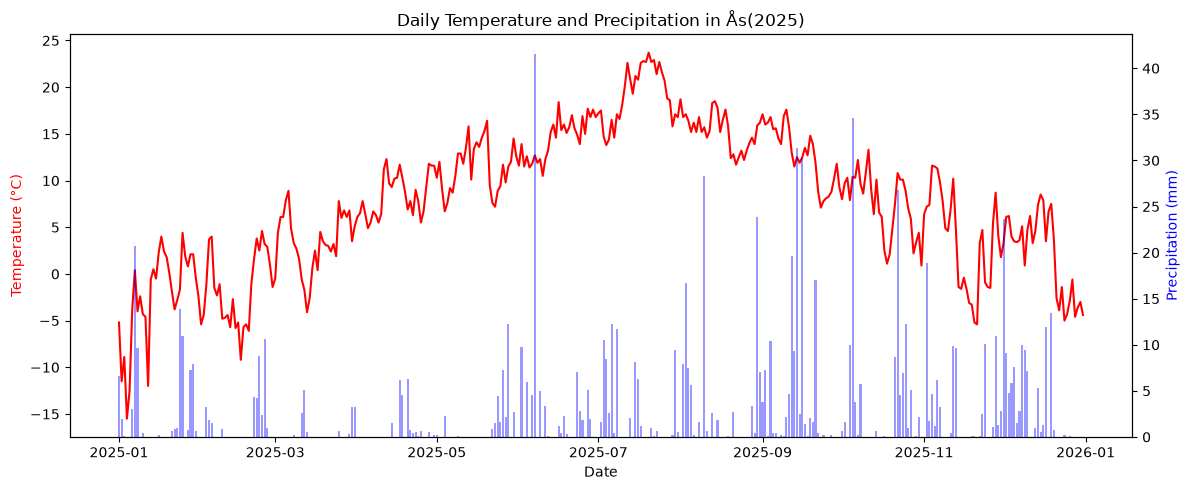

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(weather_df["date"], weather_df["temperature"], color="red")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="red")

ax2 = ax1.twinx()

ax2.bar
(weather_df["date"],
weather_df["precipitation"],
color="blue",
alpha=0.4,
)
ax2.set_ylabel("Precipitation (mm)", color="blue")

plt.title("Daily Temperature and Precipitation in Ås(2025)")
fig.tight_layout()
plt.show()

## Results and discussion:
The graph above shows the daily mean temperature in Ås. We can see general increase from January to July, and from there gradually decreasing to the end of the year. 
For the precipitation there is no clear seasonal pattern as temperature, but we can see the highest daily preciptiation recorded is durning summer. Other thing we can see is several periods of precipitation durning the end of the year. We can therfor conclude that temperature follows a clear sesonal pattern, and preciptitation varies more irregulary throughout the year. 

PT0H time offset was used to select the temperature data, and PT6H for the precipitation data. These shold be considered when comparing the tew datasets, because they may represent different 24-hour periods. The PT6H time was selected becausee it was recommended in the Frost documentation (MET Norway, n.d.). 

## Task 3: Historical temperature data
In this task, we compare daily mean temperatures in Ås from 1925 and 2025, using data retrieved from the Frost API.


In [ ]:
# Define the parameters for daily mean temperature in 1925.
historical_parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01",
}

In [ ]:
# Request historical daily temperature data from the Frost API.
historical_response = requests.get(
    endpoint,
    params=historical_parameters,
    auth=(client_id, ""),
)

print("Status code:", historical_response.status_code)

Status code: 200


In [ ]:
# Convert the API response to JSON.
historical_data = historical_response.json()

      

In [90]:
historical_temperatures = []

for day in historical_data["data"]:
    for observation in day["observations"]:
        if observation["timeOffset"] == "PT0H":
            historical_temperatures.append({
                "date": day["referenceTime"],
                "temperature": observation["value"]
            })

In [92]:
historical_df = pd.DataFrame(historical_temperatures)
historical_df["date"] = pd.to_datetime(historical_df["date"])




In [93]:
# Calculate summary statistics for the historical temperaturs.
historical_mean = historical_df["temperature"].mean()
historical_median = historical_df["temperature"].median()
historical_min = historical_df["temperature"].min()
historical_max = historical_df["temperature"].max()


In [95]:
# Compare summary statisticks for 1925 and 2025.
print(f"{'Statistic':<18}{'1925':>12}{'2025':>12}")
print("_" * 42)
print(f"{'Mean (°C)':<18} {historical_mean:>12.2f}{mean_temp:12.2f}")
print(f"{'Median (°C)':<18} {historical_median:>12.2f}{median_temp:12.2f}")
print(f"{'Min (°C)':<18} {historical_min:>12.2f}{min_temp:12.2f}")
print(f"{'Max (°C)':<18} {historical_max:>12.2f}{max_temp:12.2f}")

Statistic                 1925        2025
__________________________________________
Mean (°C)                  5.28        7.87
Median (°C)                5.30        8.30
Min (°C)                 -20.70      -15.50
Max (°C)                  24.30       23.70


In [103]:
# Creat a common day-of-year axis for both years.
df["day_of_year"] = df["date"].dt.dayofyear
historical_df["day_of_year"] = historical_df["date"].dt.dayofyear



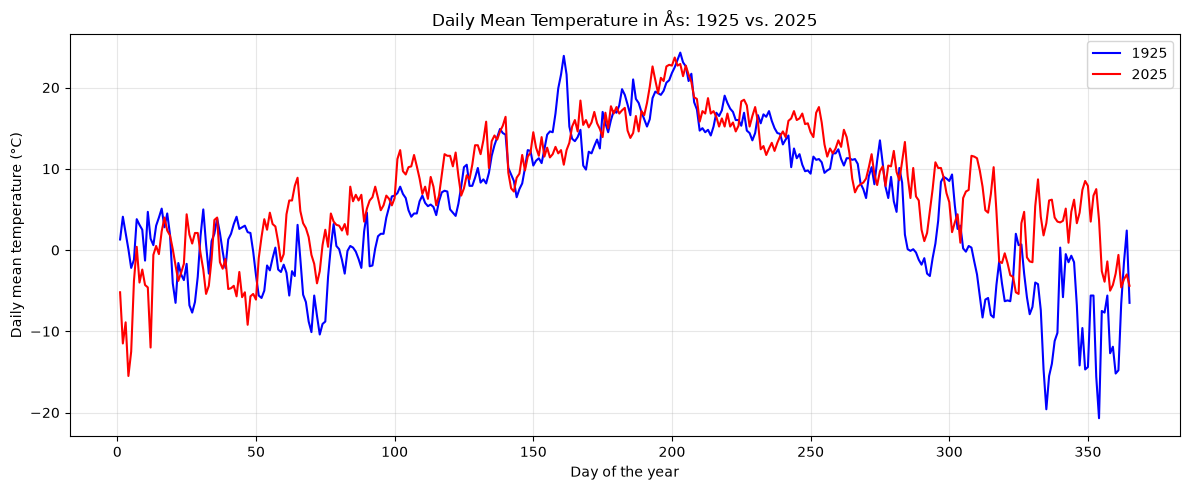

In [101]:
#Plot daily mean temperatures for 1925 and 2025.
plt.figure(figsize=(12, 5))

plt.plot(
    historical_df["day_of_year"],
    historical_df["temperature"],
    label="1925",
    color="blue",
)

plt.plot(
    df["day_of_year"],
    df["temperature"],
    label="2025",
    color="red",
)

plt.xlabel("Day of the year")
plt.ylabel("Daily mean temperature (°C)")
plt.title("Daily Mean Temperature in Ås: 1925 vs. 2025")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Results and discussion:
The graph and summary statistics show that 1925 had a lower average temperature than 2025. The mean temperature was 5.28 °C in 1925 and 7.87 °C in 2025, while the median temperatures were 5.30 °C and 8.30 °C, respectively.

The minimum temperature was −20.70 °C in 1925, compared with −15.50 °C in 2025. However, 1925 had a slightly higher maximum temperature of 24.30 °C, compared with 23.70 °C in 2025.

The graph also shows particularly low temperatures towards the end of 1925. Overall, 1925 had a wider temperature range, with both a lower minimum and a higher maximum temperature than 2025.

## Task 4: Heatwaves

## Task 5: Moving average

## References
- MET Norway. (n.d.). Frost API – Data clarifications. https://frost.met.no/dataclarifications.html.

- MET Norway. (n.d.). How to work with Frost using Python. https://frost.met.no/python_example.html.
